In [1]:
import os
from dotenv import load_dotenv
from typing import Annotated
from typing_extensions import TypedDict
from langchain_groq import ChatGroq
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_community.vectorstores import FAISS
from langchain_core.messages import HumanMessage
from langchain_core.tools import tool
from langchain.messages import SystemMessage
from langgraph.graph import StateGraph, START,END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.types import interrupt, Command
from langchain.messages import AIMessage,HumanMessage,SystemMessage
import requests
import smtplib
from email.message import EmailMessage
from langchain_community.document_loaders import PyPDFLoader
import smtplib
from email.message import EmailMessage
from html import escape
load_dotenv()


C:\Users\Azrap\AppData\Local\Temp\ipykernel_29376\4153424317.py:6: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader


True

In [2]:
llm = ChatGroq(model="openai/gpt-oss-120b", max_retries=6, reasoning_effort="low")

In [3]:
resume_path=r"C:\Users\Azrap\Downloads\resume.pdf"
linkedin_url="https://www.linkedin.com/in/azra-patvi-5ba33a31b/"
github_url="https://github.com/azrapatvi/"

In [4]:
loader=PyPDFLoader(resume_path)
resume_text="\n".join(p.page_content for p in loader.load())

In [5]:

from langchain_core.prompts import ChatPromptTemplate
draft_email_prompt = ChatPromptTemplate.from_template("""
You are a professional job application email writer.

Write a personalized, clear, and convincing application email
using the candidate's resume and details given.

use only the mentioned things like email id, job role, company if you are not sure about the details you have then ask first ...dont take these details on your own or dont fake it ...
dont go further untill and unless you dont have the given information...
if one dont know the company name then mention like 'in your company' only when nothing is mentioned...

Candidate Resume:
{resume_text}

LinkedIn Profile:
{linkedin_url}

GitHub Profile:
{github_url}


Recruiter Email:
{recruiter_email}

Job Role:
{job_role}

Company Name:
{company_name}


EMAIL STRUCTURE

1. Opening Paragraph:
- Mention the job role and company name.
- Briefly introduce the candidate.
- Express interest in the position.

2. Relevant Professional Experience:
- This section is MANDATORY.
- Mention relevant companies and job titles.
- Explain actual responsibilities and technologies used.
- Include measurable achievements when available.
- Prioritize experience relevant to the target role.
- Do not skip this section, even if the candidate has projects.

3. Relevant Project Experience:
- This section is MANDATORY and must come after professional experience.
- Select 1-3 projects relevant to the target job.
- Mention each project's name, purpose, technologies, and implementation.
- Include specific results only when supported by the resume.
- Do not combine all projects into one vague sentence.
- Do not describe every project in the resume.

4. Closing Paragraph:
- Explain briefly how the candidate's skills can contribute to the company.
- Mention that the resume is attached.
- Express interest in discussing the opportunity.

5. Signature:
- End with "Regards," followed by the candidate's actual name.
- Include the candidate's email address if available in the resume.
- Include the COMPLETE LinkedIn URL provided above.
- Include the COMPLETE GitHub URL provided above.
- Never write only "LinkedIn" or "GitHub" without their URLs.
- Never invent or modify contact details.

WRITING RULES

- Aim for 180-250 words, excluding the subject and signature.
- Never exceed 300 words.
- Use short paragraphs and clear section headings.
- Mention professional experience FIRST, then projects.
- Use a professional, natural, confident tone.
- Do not reproduce the entire resume.
- Do not invent experience, responsibilities, technologies, skills,
  projects, achievements, metrics, or qualifications.
- Use only information supported by the resume or candidate details.
- Use "Dear Hiring Manager" unless the recruiter's name is reliably known.
- Do not invent the recruiter's name.
- Do not include placeholder information.
- Do not use Markdown formatting markers such as **.
- Keep the subject concise and specific to the role and company.
- Do not invent, guess, or modify any email address or profile URL.
-do not get the recruiters email i d on your own as placeholder until and unless candidate didnt providee ask for it to the candidate.



Return the email in exactly this format:

Subject: <email_subject>

Body:
Dear Hiring Manager,

<opening paragraph>

Relevant Professional Experience:
<relevant experience with specific responsibilities>

Relevant Project Experience:
<1-3 selected projects with specific details>

<closing paragraph>

Regards,
<candidate name>
Email: <candidate email if available>
LinkedIn: <complete LinkedIn URL>
GitHub: <complete GitHub URL>
""")


In [6]:
sender_email=os.getenv("SENDER_EMAIL")
app_password = os.getenv('GMAIL_APP_PASSWORD')

In [ ]:
from langchain.tools import tool

drafts = {}

@tool
def write_email(
    company_name: str,
    job_role: str,
    recruiter_email: str,
    instructions: str = ""
):
    """Write a job application email.
    Call only when company, role and recruiter email are known.
    """

    res = (draft_email_prompt | llm).invoke({
        "resume_text": resume_text,
        "details": instructions,
        "recruiter_email": recruiter_email,
        "job_role": job_role,
        "company_name": company_name,
        "linkedin_url": linkedin_url,
        "github_url": github_url,
    })

    text = res.content.replace("**", "").strip()

    subject = f"Application for {job_role} at {company_name}"
    body = text

    if "Body:" in text:
        head, body = text.split("Body:", 1)
        subject = head.replace("Subject:", "").strip()

    drafts["subject"] = subject
    drafts["body"] = body.strip()
    drafts["recruiter_email"] = recruiter_email

    return (
        f"Draft ready.\n"
        f"Recruiter: {drafts['recruiter_email']}\n"
        f"Subject: {drafts['subject']}\n\n"
        f"{drafts['body']}"
    )

@tool
def send_email():
    """Send the currently approved draft to its saved recruiter email."""

    if not drafts.get("recruiter_email"):
        return "FAILED: Recruiter email is missing."

    if not drafts.get("subject") or not drafts.get("body"):
        return "FAILED: Email draft is missing."

    recipient = drafts["recruiter_email"]

    msg = EmailMessage()
    msg["Subject"] = drafts["subject"]
    msg["From"] = sender_email
    msg["To"] = recipient

    msg.set_content(drafts["body"])

    with open(resume_path, "rb") as f:
        msg.add_attachment(
            f.read(),
            maintype="application",
            subtype="pdf",
            filename="Azra_Patvi_Resume.pdf"
        )

    try:
        with smtplib.SMTP_SSL("smtp.gmail.com", 465) as server:
            server.login(sender_email, app_password)
            server.send_message(msg)

    except Exception as e:
        return f"FAILED to send email: {e}"

    return f"Email sent successfully to {recipient}"

In [ ]:
import re

def rewrite_email(instruction: str):
    # Check whether the user provided a new email address
    emails = re.findall(
        r'[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}',
        instruction
    )

    if emails:
        drafts["recruiter_email"] = emails[-1]

    # Rewrite the email body using the user's instructions
    res = llm.invoke(
        f"""
        Rewrite the job application email below.

        User instructions: {instruction}

        Keep the same facts, greeting and signature.
        Preserve the applicant's name, email, LinkedIn and GitHub URLs.
        Do not invent information.
        Do not include ** markers.
        Return only the email body, without a subject.

        EMAIL:
        {drafts["body"]}
        """
    )

    drafts["body"] = res.content.replace("**", "").strip()

    return (
        f"Updated recruiter: {drafts['recruiter_email']}\n"
        f"Subject: {drafts['subject']}\n\n"
        f"{drafts['body']}"
    )

In [ ]:
from langchain.agents import create_agent
from langgraph.checkpoint.memory import InMemorySaver
from langchain.agents.middleware import HumanInTheLoopMiddleware

agent=create_agent(
    model=llm,
    tools=[write_email,send_email],
    system_prompt=(
    "You are ApplyMate AI, a friendly assistant that helps users "
    "apply for jobs by email. Greet the user and chat naturally. "

    "Ask one question at a time to collect the company name, "
    "job role and recruiter email. Never guess these details. "

    "Once all details are known, call write_email to create a draft. "
    "Do not send the email automatically. The send_email tool is "
    "subject to a human approval step. "

    "If the user requests changes to the draft, use write_email "
    "with the same company, role and the latest recruiter email, "
    "including the requested changes in instructions, when appropriate. "

    "If the user changes the recruiter email, use the new address "
    "and ensure the latest address is saved before sending. "

    "After approval and execution of send_email, clearly report "
    "whether sending succeeded or failed. "
    "Then ask whether the user wants to apply somewhere else."
),
    checkpointer=InMemorySaver(),
    middleware=[
        HumanInTheLoopMiddleware(
            interrupt_on={
                "send_email":{
                    "allowed_decisions":["approve","edit","reject"],
                },
                "write_email":False
            }
        )
    ]
)

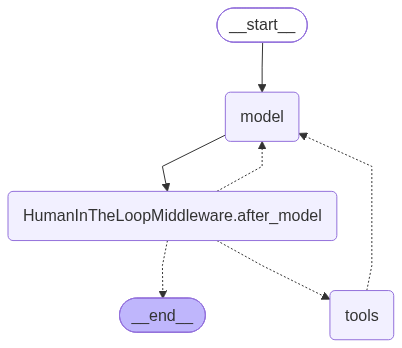

In [10]:
agent

In [11]:
from langchain.messages import HumanMessage

config={"configurable":{"thread_id":"chat1"}}

response=agent.invoke({"messages":HumanMessage(content="""My name is Azra Patvi.
        I am an AI and Data Science graduate.
        I have skills in Python and Machine Learning.
        I want to apply for an ML Engineer position at cognizant.
        in there comapny and this is the recruiters email id azrapatvi1234@gmail.com""")},config=config)

In [12]:
response

{'messages': [HumanMessage(content='My name is Azra Patvi.\n        I am an AI and Data Science graduate.\n        I have skills in Python and Machine Learning.\n        I want to apply for an ML Engineer position at cognizant.\n        in there comapny and this is the recruiters email id azrapatvi1234@gmail.com', additional_kwargs={}, response_metadata={}, id='8e12b428-128e-41db-a03a-019de452717f'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'We have company name Cognizant, role ML Engineer, recruiter email azrapatvi1234@gmail.com. Need to call write_email then send_email.', 'tool_calls': [{'id': 'fc_85cfa6fa-e0eb-4af8-8ffe-c48a7c46523e', 'function': {'arguments': '{"company_name":"Cognizant","instructions":"","job_role":"ML Engineer","recruiter_email":"azrapatvi1234@gmail.com"}', 'name': 'write_email'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 95, 'prompt_tokens': 449, 'total_tokens': 544, 'completion_time': 0.200221594, 'com

In [13]:
from langgraph.types import Command

if "__interrupt__" in response:
    print("paused the execution")

    response=agent.invoke(
        Command(
            resume={
                "decisions":[
                    {"type":"approve"}
                ]
            }
        ),config=config
    )

    print(response['messages'][-1].content)

paused the execution
Your application email has been sent successfully to **azrapatvi1234@gmail.com**.

Would you like to apply for another position elsewhere?


In [ ]:
while "__interrupt__" in response:
    while True:
        print("\nRecruiter:", drafts["recruiter_email"])
        print("Subject:", drafts["subject"])
        print(drafts["body"])

        answer = input(
            "\nType yes to send, no to cancel, "
            "or enter your changes: "
        ).strip()

        if answer.lower() in ["yes", "y"]:
            decision = {"type": "approve"}
            break

        elif answer.lower() in ["no", "n"]:
            decision = {
                "type": "reject",
                "message": "User cancelled. Do not send."
            }
            break

        else:
            rewrite_email(answer)
            print("\nDraft updated. Review it before sending.")
            # Loop again so the user sees the updated draft.

    response = agent.invoke(
        Command(resume={"decisions": [decision]}),
        config=config
    )


YOU:  hi
BOT:  Hi again! 👋 How can I assist you today? Whether it’s another job application, polishing a resume, or anything else, just let me know!

YOU:  capgemini
BOT:  Great! Which job role are you interested in applying for at Capgemini?

YOU:  ai/ml
BOT:  Got it. Could you specify the exact title (e.g., “AI Engineer,” “Machine Learning Scientist,” “Data Scientist – AI/ML,” etc.) you’d like to apply for at Capgemini?Sure thing—just let me know the precise job title you’re targeting at Capgemini, and we’ll move forward!

YOU:  AI Engineer
BOT:  Sure! Could you provide the recruiter’s email address for the AI Engineer position at Capgemini?

Subject: Application for AI Engineer Position at Capgemini
Dear Hiring Manager,

I am writing to apply for the AI Engineer role at Capgemini. I am currently pursuing a B.Tech in Artificial Intelligence and Data Science and have accumulated hands‑on experience in data science, machine learning, and AI integration through internships and personal